# Cuenta Estaciones 

In [8]:
"""
Cuenta nuemro de eventos registrados por las estaciones sismológicas
leyendo el archivo select.out
"""
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def cuenta_estaciones(fname):
    import re
    try:
        fhand = open(fname)
    except:
        print('No se puede abrir el archivo ', fname)
        exit()
        
    parsing = False
    estaciones = list()
    # Extrae codigos de estaciones leyendo lineas que estan entre STAT y 
    # la linea vacía  
        
    for line in fhand:
        line = line.rstrip() #elimina blanks
                 
        if re.match('^ STAT ',line):
            parsing = True
        elif line=='':
            parsing = False
       
        if parsing and not re.match('^ STAT ',line):
            if re.findall('P ',line):
                sta = line.split()
                estaciones.append(sta[0])
    
    # Cuenta el numero de veces que se repite cada nombre de estacion
    cuenta_dict = dict()
    
    for st in estaciones:
        cuenta_dict[st] = cuenta_dict.get(st,0)+1
    
    year=fname[-8:-4]
    nombre = fname.split('.')[0][7:].replace(year,'')
    #nombre = nombre2.replace('2022','')  
    
    df_est=(pd.DataFrame(cuenta_dict.items(), 
            columns=['Estacion',nombre])
            .set_index('Estacion')
            .sort_index()
           )
    
    return(df_est)


In [11]:
def plot_grafico():
    plt.figure(figsize=(8,10))
    ax=plt.gca()

    #bars=sbn.barplot(x="numero", y="estaciones", data=est_usdf,edgecolor='black', color="steelblue",alpha=0.9)
    bars=plt.barh(est_usdf.estaciones, est_usdf.numero, align='center',height = 0.8,color='steelblue',alpha=0.9)

    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['top'].set_linewidth(1.2)

    ax.text(x=0,y=-4.0,s='Número de sismos detectados por las estaciones sismológicas',size=12,weight='bold')
    ax.text(x=0,y=-3.2,s='durante el mes de enero de 2022',size=12, weight='bold')

    ax.tick_params(which='major',length=7,labelsize=12,labelbottom=True)
    ax.xaxis.grid(True, which='major',linewidth=1.0)
    ax.xaxis.tick_top()
    ax.set_ylabel('Estaciones',fontsize=14,weight='bold')
    ax.set_xlabel('')
    ax.invert_yaxis()
    ax.set_xlim(0,140)
    for bar in bars:
        ax.text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2, str(bar.get_width()), 
                va='center', color='k', fontsize=11)

    #plt.savefig("sismos_estaciones.png",dpi=300, bbox_inches='tight')


In [12]:
# Crea lista con los nombres de los archivos select
mes_ab=['ene','feb','mar','abr','may','jun','jul','ago'] # ,'oct','nov','dic']
filename=['select_'+x+'.out' for x in mes_ab]
#filename
#Crea lista de dataframes que se juntaran con pd.merge
lista = [cuenta_estaciones(file) for file in filename]
#ista_f = [file for file in filename]


In [17]:
no_incluir = ['ACPR','ACTION','ARGC','ANWB','BAR2','BCIP','BBGH','BIM','CRJC','FLO2', 'GCMP','GRGR','HEL',
              'JTS','LCBC','MTDJ','NOR','OCA','OLDACT','ROSC','RUS','SJC','TAM','TRN', 'URE','URI','ZAR']


from functools import reduce
result_2 = reduce(lambda df_left,df_right: 
                  pd.merge(df_left, df_right, 
                  left_index=True, right_index=True, 
                   how='outer'), lista).fillna(0).astype(int)

result_3 = result_2.drop(no_incluir)
result_3.to_json('historico_estaciones.json',orient='index',indent=4)
#import seaborn as sns
#fig, ax =plt.subplots(figsize=(8,10),dpi=500)
#sns.heatmap(result_3,ax=ax,cmap='RdBu_r',annot=True,fmt='3d')
#ax.set_title('No sismos detectados por estación en 2026', fontsize=14)
#ax.set_ylabel('')
#plt.savefig('Estaciones2026b.png', dpi=500)

In [7]:
lista[0]

,ene
Estacion,
ACPR,11
ARGC,12
BAR2,41
BBGH,4
BENV,63
BIM,4
CARV,9
CRJC,34
FLO2,3


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

def cuenta_estaciones(fname):
    import re
    try:
        fhand = open(fname)
    except:
        print('No se puede abrir el archivo ', fname)
        exit()
        
    parsing = False
    estaciones = list()
    # Extrae codigos de estaciones leyendo lineas que estan entre STAT y 
    # la linea vacía  
        
    for line in fhand:
        line = line.rstrip() #elimina blanks
                 
        if re.match('^ STAT ',line):
            parsing = True
        elif line=='':
            parsing = False
       
        if parsing and not re.match('^ STAT ',line):
            if re.findall('P ',line):
                sta = line.split()
                estaciones.append(sta[0])
    
    # Cuenta el numero de veces que se repite cada nombre de estacion
    count = dict()
    
    for st in estaciones:
        count[st] = count.get(st,0)+1
    
    # Crea una lista de tuples nombres y cuentas
    lst = list()
    for k,v in count.items():
        lst.append((v,k))
    
    lst.sort(reverse=False)
    est_usdf = pd.DataFrame(lst)
    est_usdf.columns=['numero','estaciones']
    est_usdf.sort_values(['numero'],ascending=False,inplace=True)
    est_usdf.reset_index(inplace=True,drop=True)
    return(est_usdf)
    

In [4]:

def plot_grafico():
    plt.figure(figsize=(8,10))
    ax=plt.gca()

    #bars=sbn.barplot(x="numero", y="estaciones", data=est_usdf,edgecolor='black', color="steelblue",alpha=0.9)
    bars=plt.barh(est_usdf.estaciones, est_usdf.numero, align='center',height = 0.8,color='steelblue',alpha=0.9)

    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['top'].set_linewidth(1.2)

    ax.text(x=0,y=-4.0,s='Número de sismos detectados por las estaciones sismológicas',size=12,weight='bold')
    ax.text(x=0,y=-3.2,s='durante el mes de enero de 2022',size=12, weight='bold')

    ax.tick_params(which='major',length=7,labelsize=12,labelbottom=True)
    ax.xaxis.grid(True, which='major',linewidth=1.0)
    ax.xaxis.tick_top()
    ax.set_ylabel('Estaciones',fontsize=14,weight='bold')
    ax.set_xlabel('')
    ax.invert_yaxis()
    ax.set_xlim(0,140)
    for bar in bars:
        ax.text(bar.get_width()+0.5, bar.get_y()+bar.get_height()/2, str(bar.get_width()), 
                va='center', color='k', fontsize=11)

    plt.savefig("sismos_estaciones.png",dpi=300, bbox_inches='tight')

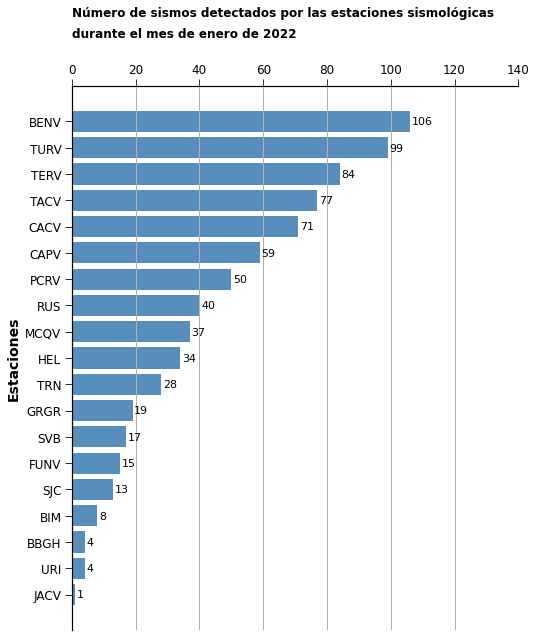

In [7]:
est_usdf =  cuenta_estaciones("select_ene2022.out")
plot_grafico()